# Statistical Shape Modeling Pipeline for the Femur Bone
Luke Doladille, Dec. 27, 2025

### 0: CREATING THE PROJECT ENVIRONMENT

#### 0.1: IMPORTING THE LIBRARIES USEFUL FOR THE PROJECT


In [ ]:
import re
from time import time
import numpy as np
from scipy.spatial import KDTree
import pyvista as pv
import os
from pycpd import DeformableRegistration
import time 
import open3d as o3d
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

np.random.seed(42)

#### 0.2: SETTING THE CORRECT WORKING DIRECTORY

In [36]:
current_path = os.getcwd()
print(current_path) # Make sure to be in the "data" folder
new_path= "C:/Users/luked/OneDrive/Documents/SJTU/BME8113-Advanced-Intraoperative-Imaging-Techniques/SSM/data"
os.chdir(new_path)
print(os.getcwd()) # Should be in the main project folder now


C:\Users\luked\OneDrive\Documents\SJTU\BME8113-Advanced-Intraoperative-Imaging-Techniques\SSM\data
C:\Users\luked\OneDrive\Documents\SJTU\BME8113-Advanced-Intraoperative-Imaging-Techniques\SSM\data


#### 0.3: LOADING THE DATA "MANUALLY" FROM .IV FILES

In [37]:
def read_iv_file_manually(file_path):
    """
    Manually parses an ASCII Open Inventor (.iv) file to extract vertices.
    """
    with open(file_path, 'r') as f:
        content = f.read()

    # 1. Find the coordinate block. 
    # Look for 'Coordinate3' followed eventually by 'point ['
    # This regex looks for the content inside point [ ... ]
    match = re.search(r'point\s*\[([^\]]+)\]', content, re.DOTALL)
    
    if not match:
        raise ValueError(f"Could not find 'point [...]' block in {file_path}. Is it binary?")

    # 2. Extract the text block containing numbers
    point_data_str = match.group(1)

    # 3. Clean up formatting (remove commas, newlines)
    # Replace commas with spaces to handle "1.0, 2.0, 3.0" format
    point_data_str = point_data_str.replace(',', ' ')
    
    # 4. Convert to numpy array
    try:
        # Parse all numbers from the string
        values = np.fromstring(point_data_str, sep=' ')
        
        # Reshape into (N, 3) for X, Y, Z coordinates
        points = values.reshape(-1, 3)
        return points
        
    except Exception as e:
        print(f"Error parsing points in {file_path}: {e}")
        return None

all_femurs_points = []
file_prefix = ["001", "002", "004", "005", "006", "007", "008", "009", "010",
    "011", "013", "014", "015", "016", "017", "018", "019", "020", 
    "021", "022"]
iv_files = [f"{prefix}.iv" for prefix in file_prefix]
count = 0

#### 0.4: TEST FUNCTION TO CHECK SIZE AND DIMENSION OF EACH LOADED POINT CLOUD

In [38]:
for filename in iv_files:
    pts = read_iv_file_manually(filename)
    print(pts.shape[0], pts.shape[1])
    if pts is not None:
        count += 1
        all_femurs_points.append(pts)

print(count)
print(f"Loaded {len(all_femurs_points)} femurs.")
print(np.median([len(pts) for pts in all_femurs_points]))
print(np.min([len(pts) for pts in all_femurs_points]))
print(np.max([len(pts) for pts in all_femurs_points]))

66100 3
48515 3
73521 3
66651 3
75746 3
72103 3
67317 3
57168 3
56928 3
82841 3
68261 3
71273 3
62754 3
76055 3
60362 3
65991 3
69168 3
60309 3
55772 3
78863 3
20
Loaded 20 femurs.
66984.0
48515
82841


#### 0.5: VISUALIZATION FUNCTIONS FOR POINT CLOUDS

In [39]:
def _maybe_downsample(pts, n):
    if n is None or pts.shape[0] <= n:
        return pts
    idx = np.random.choice(pts.shape[0], n, replace=False)
    return pts[idx]

def visualize_point_clouds_overlaid(point_list, downsample, point_size=3):
    """
    Overlay all point clouds in one PyVista window. Pass either all_femurs_points
    or [t['aligned_mesh'] for t in transformations] to `point_list`.
    """
    plt = pv.Plotter()
    for i, pts in enumerate(point_list):
        pts_ds = _maybe_downsample(np.asarray(pts), downsample)
        cloud = pv.PolyData(pts_ds)
        color = tuple(np.random.rand(3))
        plt.add_points(cloud, color=color, point_size=point_size, render_points_as_spheres=True, name=f"pc{i}")
    plt.add_axes()
    plt.show()

def visualize_point_clouds_grid(point_list, downsample=2000, ncols=5, point_size=3):
    """
    Show each point cloud in its own subplot (grid). Good for quick per-sample inspection.
    """
    n = len(point_list)
    nrows = int(np.ceil(n / ncols))
    plotter = pv.Plotter(shape=(nrows, ncols), notebook=False)
    for i, pts in enumerate(point_list):
        r = i // ncols
        c = i % ncols
        plotter.subplot(r, c)
        pts_ds = _maybe_downsample(np.asarray(pts), downsample)
        plotter.add_points(pv.PolyData(pts_ds), point_size=point_size, render_points_as_spheres=True)
        plotter.add_text(f"#{i}", font_size=10)
        plotter.add_axes()
    # empty subplots cleanup
    for i in range(n, nrows * ncols):
        r = i // ncols
        c = i % ncols
        plotter.subplot(r, c)
        plotter.add_text("", font_size=1)
    plotter.show()

def quick_mpl_3d(point_list, downsample=1000, size=1):
    """
    Very lightweight 3D scatter (non-interactive or for notebooks) using matplotlib.
    """
    import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    for pts in point_list:
        pts_ds = _maybe_downsample(np.asarray(pts), downsample)
        ax.scatter(pts_ds[:, 0], pts_ds[:, 1], pts_ds[:, 2], s=size, alpha=0.6)
    plt.show()

### 1. ICP IMPLEMENTATION FOR THE SCALED RIGID REGISTRATION

#### 1.1: DOWNSAMPLING FUNCTION

We perform a downsampling of the meshes in order to speed up the registration process. 
This is especially useful for ICP, which could not be performed with the original point clouds due to their excessive size. 

In [40]:
def farthest_point_sampling(points, k):
    """
    Selects k points from the point cloud such that they are 
    maximally distant from each other.
    
    Input:
        points: (N, 3) numpy array
        k: int, number of points to select
    Output:
        selected_points: (k, 3) numpy array
        indices: list of indices selected
    """
    N, D = points.shape
    
    if N < k:
        raise ValueError(f"Input has fewer points ({N}) than requested k ({k}).")

    # Array to store the "distance to the nearest selected point" for every point
    # Initialize with Infinity
    min_distances = np.full(N, np.inf)
    
    selected_indices = []
    
    # 1. Pick the first point randomly
    current_idx = np.random.randint(0, N)
    selected_indices.append(current_idx)
    
    # Loop until we have k points
    for _ in range(k - 1):
        # Get the coordinates of the last added point
        last_added_point = points[current_idx]
        
        # 2. Compute Euclidean distance (squared) from the last added point to ALL points
        # shape (N,)
        dist_to_last = np.sum((points - last_added_point)**2, axis=1)
        
        # 3. Update the minimum distance for every point
        # A point keeps its old distance unless the new point is closer
        min_distances = np.minimum(min_distances, dist_to_last)
        
        # 4. Pick the point that is farthest from the current set
        # (The one with the largest 'minimum distance')
        current_idx = np.argmax(min_distances)
        selected_indices.append(current_idx)
        
    return points[selected_indices]

#### 1.2: COMPUTE SIMILARITY TRANSFORM FUNCTION

In [41]:
def compute_similarity_transform(source_points, target_points):
    """
    Calculates the Rotation (R), Translation (t), and Scale (s) that best 
    aligns source_points to target_points.
    
    Input:  Nx3 arrays of corresponding points
    Output: R (3x3), t (3x1), s (scalar)
    """
    # 1. Compute Centroids
    centroid_source = np.mean(source_points, axis=0)
    centroid_target = np.mean(target_points, axis=0)

    # 2. Center the points
    source_centered = source_points - centroid_source
    target_centered = target_points - centroid_target

    # 3. Compute Scale (s)
    # s = sqrt( var(target) / var(source) )
    var_source = np.sum(np.square(source_centered))
    var_target = np.sum(np.square(target_centered))
    s = np.sqrt(var_target / var_source)

    # 4. Compute Rotation (R) using SVD
    # H = (Source_Centered * s)^T * Target_Centered
    H = np.dot((source_centered * s).T, target_centered)
    
    U, D, Vt = np.linalg.svd(H)
    R = np.dot(Vt.T, U.T)

    # Handle reflection case (determinant is -1)
    if np.linalg.det(R) < 0:
        Vt[2, :] *= -1
        R = np.dot(Vt.T, U.T)

    # 5. Compute Translation (t)
    t = centroid_target - s * np.dot(R, centroid_source)

    return R, t, s

#### 1.3: ICP FUNCTION (ITERATIVE CLOSEST POINT WITH SCALING) 

In [42]:
def icp_scaled(source_points, target_points, max_iterations=50, tolerance=1e-5):

    current_source = source_points.copy()
    prev_error = float('inf')
    
    # Find closest points using KDTree for efficiency
    tree = KDTree(target_points)
    
    for i in range(max_iterations):

        # 1. Retrieve point correspondences
        distances, indices = tree.query(current_source)
        matched_target_points = target_points[indices]
        
        # 2. Compute Transform for THIS STEP
        R_step, t_step, s_step = compute_similarity_transform(current_source, matched_target_points)
        
        # 3. Apply Transform
        current_source = s_step * np.dot(current_source, R_step.T) + t_step
        
        # 4. Check Error
        mean_error = np.mean(distances)
        if np.abs(prev_error - mean_error) < tolerance:
            break
        prev_error = mean_error
    
    # Re-calculate the TOTAL transform from the original input to the final result
    final_R, final_t, final_s = compute_similarity_transform(source_points, current_source)
        
    return current_source, final_R, final_t, final_s

#### 1.4: EXECUTION OF THE SCALED RIGID REGISTRATION FOR ALL FEMURS

The initial reference shape is chosen as the 10th femur (index 9), since it is of maximal resolution. 
This will be our fixed points (template) for the ICP registration.
The moving points (source) will be each of the other femurs in the dataset. 

The transformation data are stored in the transformations list: 

In [43]:
transformations = []

##### 1.4.1: ALL FEMURS DOWNSAMPLED TO 1K POINTS. 

In [44]:
template_raw = all_femurs_points[9]
template_low = farthest_point_sampling(template_raw, 1000) 

femurs_downsampled = []

for i in range(len(all_femurs_points)):
    femurs_downsampled.append(farthest_point_sampling(all_femurs_points[i], 1000))

femurs_downsampled[9] = template_low  # Ensure the template is the downsampled version

##### 1.4.2: ICP EXECUTION


In [45]:
for i in range(len(femurs_downsampled)):
    print(f"Registering femur {i}...")
    
    # Run Scaled Registration
    aligned_points, R, t, s = icp_scaled(femurs_downsampled[i], template_low)
    
    # Store
    transform_data = {
        "id": i,
        "rotation": R,       
        "translation": t,    
        "scale": s,          
        "aligned_mesh": aligned_points
    }
    transformations.append(transform_data)

Registering femur 0...
Registering femur 1...
Registering femur 2...
Registering femur 3...
Registering femur 4...
Registering femur 5...
Registering femur 6...
Registering femur 7...
Registering femur 8...
Registering femur 9...
Registering femur 10...
Registering femur 11...
Registering femur 12...
Registering femur 13...
Registering femur 14...
Registering femur 15...
Registering femur 16...
Registering femur 17...
Registering femur 18...
Registering femur 19...


##### 1.4.3: ICP OUTCOME VISUALIZATION

Femur 0: Scale = 0.9989
Femur 0: Cloud_size = 1000
Femur 1: Scale = 1.0507
Femur 1: Cloud_size = 1000
Femur 2: Scale = 0.7810
Femur 2: Cloud_size = 1000
Femur 3: Scale = 0.8976
Femur 3: Cloud_size = 1000
Femur 4: Scale = 0.9555
Femur 4: Cloud_size = 1000
Femur 5: Scale = 0.9859
Femur 5: Cloud_size = 1000
Femur 6: Scale = 0.9413
Femur 6: Cloud_size = 1000
Femur 7: Scale = 1.0118
Femur 7: Cloud_size = 1000
Femur 8: Scale = 1.0004
Femur 8: Cloud_size = 1000
Femur 9: Scale = 1.0000
Femur 9: Cloud_size = 1000
Femur 10: Scale = 0.9097
Femur 10: Cloud_size = 1000
Femur 11: Scale = 1.0144
Femur 11: Cloud_size = 1000
Femur 12: Scale = 0.8717
Femur 12: Cloud_size = 1000
Femur 13: Scale = 1.0049
Femur 13: Cloud_size = 1000
Femur 14: Scale = 0.9704
Femur 14: Cloud_size = 1000
Femur 15: Scale = 0.9962
Femur 15: Cloud_size = 1000
Femur 16: Scale = 0.9244
Femur 16: Cloud_size = 1000
Femur 17: Scale = 0.9891
Femur 17: Cloud_size = 1000
Femur 18: Scale = 1.0318
Femur 18: Cloud_size = 1000
Femur 19: Sca

c:\Users\luked\anaconda3\lib\site-packages\pyvista\jupyter\notebook.py:37: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (c:\Users\luked\anaconda3\lib\site-packages\trame\widgets\__init__.py)

Falling back to a static output.
  warnings.warn(


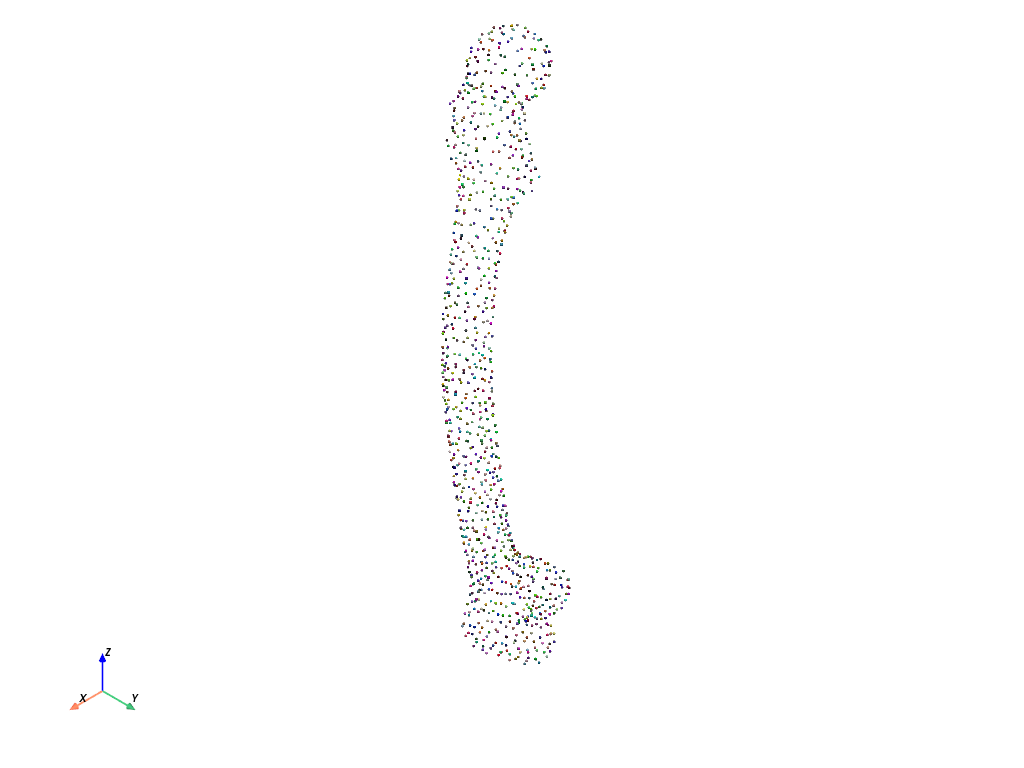

In [46]:
for i in range(len(transformations)):
    print(f"Femur {i}: Scale = {transformations[i]['scale']:.4f}")
    print(f"Femur {i}: Cloud_size = {len(transformations[i]['aligned_mesh'])}")

visualize_point_clouds_grid([t['aligned_mesh'] for t in transformations], downsample=1000, ncols=5)
visualize_point_clouds_grid([t['aligned_mesh'] for t in transformations], downsample=1000, ncols=5)
visualize_point_clouds_overlaid(template_low, downsample=1000, point_size=3)


### 2. DEFORMABLE REGISTRATION USING CPD

#### 2.1: DEFORMABLE REGISTRATION FUNCTION

In [ ]:
def deformable_registration_cpd(template_points, target_points, alpha=3.0, beta=2.0):
    """
    Deforms the template_points to match the target_points using CPD.
    
    Parameters:
    - alpha: Smoothness weight (higher = more rigid/smooth deformation)
    - beta:  Width of the Gaussian filter (interaction between points)
    """
    print(f"Starting CPD: Template ({len(template_points)} pts) -> Target ({len(target_points)} pts)")
    
    # Initialize the Deformable Registration object
    # X = Target (Fixed), Y = Source (Moving/Deforming)
    reg = DeformableRegistration(X=target_points, Y=template_points, alpha=alpha, beta=beta)
    
    # Run the registration
    # output_points is the template DEFORMED to look like the target
    output_points, _ = reg.register()
    
    return output_points


#### 2.2: DEFORMABLE REGISTRATION EXECUTION

In [ ]:
aligned_dataset = [] # Stores the SSM-ready data

# Use the aligned mesh from the reference subject (output of ICP) as the template
template = transformations[9]["aligned_mesh"]  # aligned atlas

# Deform the template to each other aligned subject (target = aligned_mesh from ICP)
for i in range(len(transformations)):
    start_time = time.time()

    if i!=9:
        target = transformations[i]["aligned_mesh"]
        print(f"Deforming template to Subject {i}...")
        # CPD will deform template (Y) to match target (X)
        deformed_shape = deformable_registration_cpd(template, target)
        aligned_dataset.append(deformed_shape)
    else:
        # For the template itself, just add it directly
        aligned_dataset.append(template)
        
    end_time = time.time()
    duration = end_time - start_time
    print(f"Finished Subject {i} in {duration:.2f} seconds.")
    print(f"New shape has {len(deformed_shape)} vertices.\n")

# Check: All meshes in aligned_dataset should now have the same length as the template
print(f"Final check: {[len(p) for p in aligned_dataset]}")

Deforming template to Subject 0...
Starting CPD: Template (1000 pts) -> Target (1000 pts)
Finished Subject 0 in 26.20 seconds.
New shape has 1000 vertices.

Deforming template to Subject 1...
Starting CPD: Template (1000 pts) -> Target (1000 pts)
Finished Subject 1 in 27.43 seconds.
New shape has 1000 vertices.

Deforming template to Subject 2...
Starting CPD: Template (1000 pts) -> Target (1000 pts)
Finished Subject 2 in 30.13 seconds.
New shape has 1000 vertices.

Deforming template to Subject 3...
Starting CPD: Template (1000 pts) -> Target (1000 pts)
Finished Subject 3 in 23.42 seconds.
New shape has 1000 vertices.

Deforming template to Subject 4...
Starting CPD: Template (1000 pts) -> Target (1000 pts)
Finished Subject 4 in 27.82 seconds.
New shape has 1000 vertices.

Deforming template to Subject 5...
Starting CPD: Template (1000 pts) -> Target (1000 pts)
Finished Subject 5 in 26.70 seconds.
New shape has 1000 vertices.

Deforming template to Subject 6...
Starting CPD: Template 

### 3: PCA, Visualizations, Results 

#### 3.1: PCA

In [ ]:
# Convert (20, N, 3) meshes into (20, N*3) vectors
n_samples = len(aligned_dataset)
n_points = aligned_dataset[0].shape[0]

# Flatten: [x1, y1, z1, x2, y2, z2...]
data_matrix = np.array([mesh.flatten() for mesh in aligned_dataset])
print(f"Data Matrix Shape: {data_matrix.shape}")

# 2. Perform PCA
pca = PCA() # Keep all components for now
pca.fit(data_matrix)

mean_vector = pca.mean_
eigenvalues = pca.explained_variance_
eigenvectors = pca.components_

print("PCA Completed.")

c:\Users\luked\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Data Matrix Shape: (20, 3000)
PCA Completed.


#### 3.2: Visualization

In [ ]:
def visualize_mode_side_by_side(mean_vec, eigen_vecs, eigen_vals, mode_index, scale_factor=3.0):
    """
    Visualizes -3SD, Mean, and +3SD for a specific mode side-by-side.
    
    Parameters:
    - mode_index: Which mode to visualize (0 = Mode 1, 1 = Mode 2...)
    - scale_factor: How many standard deviations to deform (usually 3.0)
    """
    
    # 1. Reconstruct the Three Shapes
    std_dev = np.sqrt(eigen_vals[mode_index])
    
    # Mean Shape
    shape_mean = mean_vec.reshape(-1, 3)
    
    # -3 Sigma Shape
    shape_minus = (mean_vec - scale_factor * std_dev * eigen_vecs[mode_index]).reshape(-1, 3)
    
    # +3 Sigma Shape
    shape_plus = (mean_vec + scale_factor * std_dev * eigen_vecs[mode_index]).reshape(-1, 3)
    
    # 2. Convert to Open3D Point Clouds & Assign Colors
    # Helper to create a cloud
    def create_pcd(points, color, offset_x):
        pcd = o3d.geometry.PointCloud()
        pcd.points = o3d.utility.Vector3dVector(points)
        pcd.paint_uniform_color(color)
        
        # Translate along X axis so they don't overlap
        # We calculate the width of the bone to know how far to shift
        pcd.translate((offset_x, 0, 0)) 
        return pcd

    # Calculate shift distance (width of the bone + gap)
    width = np.ptp(shape_mean[:, 0]) # Peak-to-peak distance on X axis
    spacing = width * 1.5 

    # Create the objects
    # Left: -3SD (Blue)
    pcd_minus = create_pcd(shape_minus, [0, 0, 1], -spacing) 
    
    # Center: Mean (Gray)
    pcd_mean  = create_pcd(shape_mean,  [0.7, 0.7, 0.7], 0)      
    
    # Right: +3SD (Red)
    pcd_plus  = create_pcd(shape_plus,  [1, 0, 0], spacing)      

    # 3. Visualization
    print(f"Visualizing Mode {mode_index + 1}...")
    print("Left (Blue): -3 SD | Middle (Gray): Mean | Right (Red): +3 SD")
    
    o3d.visualization.draw_geometries([pcd_minus, pcd_mean, pcd_plus], 
                                      window_name=f"Mode {mode_index + 1} Variation",
                                      width=1200, height=600)

# --- EXECUTE ---
# Visualize Mode 1 (The most significant variation)
visualize_mode_side_by_side(mean_vector, eigenvectors, eigenvalues, mode_index=0)

# Visualize Mode 2
visualize_mode_side_by_side(mean_vector, eigenvectors, eigenvalues, mode_index=1)

Visualizing Mode 1...
Left (Blue): -3 SD | Middle (Gray): Mean | Right (Red): +3 SD
Visualizing Mode 2...
Left (Blue): -3 SD | Middle (Gray): Mean | Right (Red): +3 SD
[Open3D WARNING] [ViewControl] SetViewPoint() failed because window height and width are not set.


#### 3.3: Results

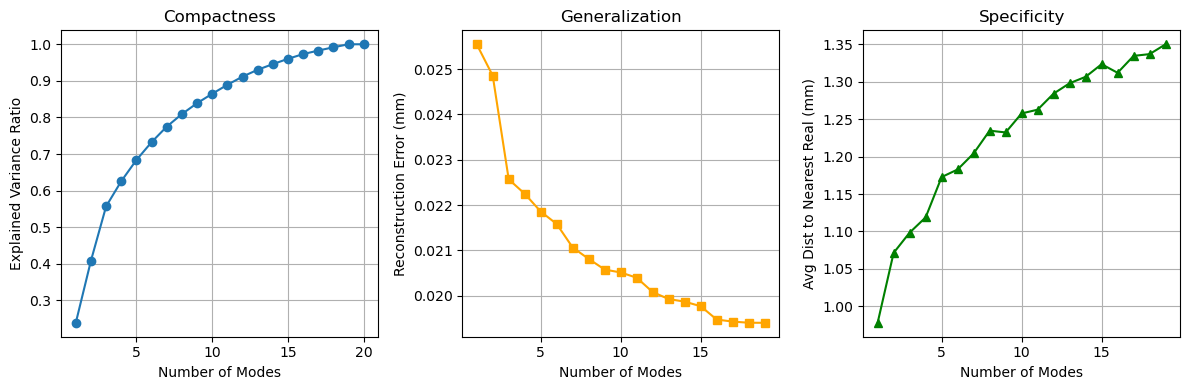

95% Variance explained by first 15 modes.


In [ ]:
def calculate_metrics(data_matrix):
    
    # --- 1. COMPACTNESS ---
    # How much variance is explained by K modes?
    pca_full = PCA()
    pca_full.fit(data_matrix)
    cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
    
    x_axis_compactness = range(1, len(cumulative_variance) + 1)

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1)
    plt.plot(x_axis_compactness, cumulative_variance, marker='o')
    plt.xlabel('Number of Modes')
    plt.ylabel('Explained Variance Ratio')
    plt.title('Compactness')
    plt.grid(True)

    # --- 2. GENERALIZATION ---
    # Leave-One-Out Cross Validation: Can we reconstruct the excluded shape?
    n_samples = data_matrix.shape[0]
    gen_errors = []
    
    # Test for M modes (e.g., 1 to 20)
    max_modes = min(n_samples - 1, 20)
    mode_range = range(1, max_modes + 1)
    
    for m in mode_range:
        errors = []
        for i in range(n_samples):
            # Train on all except i
            train_data = np.delete(data_matrix, i, axis=0)
            test_shape = data_matrix[i]
            
            # Fit PCA
            pca_loo = PCA(n_components=m)
            pca_loo.fit(train_data)
            
            # Reconstruct the left-out shape
            coeffs = pca_loo.transform(test_shape.reshape(1, -1))
            recon = pca_loo.inverse_transform(coeffs)
            
            # Calculate RMSE
            error = np.sqrt(np.mean((test_shape - recon)**2))
            errors.append(error)
        
        gen_errors.append(np.mean(errors))

    plt.subplot(1, 3, 2)
    plt.plot(mode_range, gen_errors, marker='s', color='orange')
    plt.xlabel('Number of Modes')
    plt.ylabel('Reconstruction Error (mm)')
    plt.title('Generalization')
    plt.grid(True)

    # --- 3. SPECIFICITY ---
    # Generate random shapes from the model and check if they look "real"
    # (Distance to nearest training sample)
    spec_errors = []
    n_random_samples = 1000
    
    pca_spec = PCA()
    pca_spec.fit(data_matrix)
    
    for m in mode_range:
        # Generate random coefficients within reasonable bounds (+/- 1 std dev usually)
        # Note: We use the eigenvalues from the FULL model, truncated to m
        current_eigs = pca_spec.explained_variance_[:m]
        
        # Generate random samples: Mean + sum( rand * sqrt(lambda) * eigenvector )
        # Shape: (1000, m)
        rand_coeffs = np.random.randn(n_random_samples, m) * np.sqrt(current_eigs)
        
        # Reconstruct these phantom shapes
        # (1000, m) x (m, features) = (1000, features)
        generated_shapes = np.dot(rand_coeffs, pca_spec.components_[:m]) + pca_spec.mean_
        
        # Find distance to NEAREST real training sample for each generated shape
        min_dists = []
        for gen_shape in generated_shapes:
            # Distance to all real samples
            dists = np.linalg.norm(data_matrix - gen_shape, axis=1)
            min_dists.append(np.min(dists))
            
        spec_errors.append(np.mean(min_dists))

    plt.subplot(1, 3, 3)
    plt.plot(mode_range, spec_errors, marker='^', color='green')
    plt.xlabel('Number of Modes')
    plt.ylabel('Avg Dist to Nearest Real (mm)')
    plt.title('Specificity')
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()

    # Print summary
    print(f"95% Variance explained by first {np.argmax(cumulative_variance >= 0.95) + 1} modes.")

# --- EXECUTE ---
calculate_metrics(data_matrix)

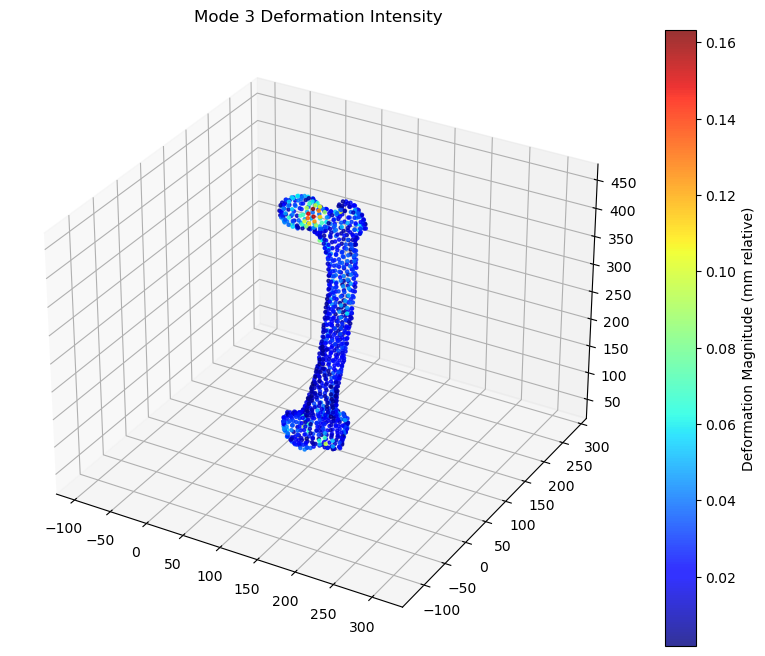

In [49]:
def plot_eigenvector_heatmap(mean_vec, eigen_vecs, mode_index=0):
    """
    Plots the Mean Shape colored by the Magnitude of the Eigenvector.
    Red = High Deformation Area
    Blue = Low Deformation Area
    """
    # 1. Reshape
    mean_geometry = mean_vec.reshape(-1, 3)
    eigen_geometry = eigen_vecs[mode_index].reshape(-1, 3)
    
    # 2. Calculate Magnitude (Euclidean Norm) of deformation at each vertex
    # axis=1 calculates sqrt(x^2 + y^2 + z^2) for each row
    magnitudes = np.linalg.norm(eigen_geometry, axis=1)
    
    # 3. Plot
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    # Scatter plot with color mapping (cmap='jet' or 'coolwarm')
    img = ax.scatter(mean_geometry[:, 0], mean_geometry[:, 1], mean_geometry[:, 2], 
                     c=magnitudes, cmap='jet', s=5, alpha=0.8)
    
    fig.colorbar(img, ax=ax, label="Deformation Magnitude (mm relative)")
    ax.set_title(f"Mode {mode_index + 1} Deformation Intensity")
    
    # Same axis scaling logic
    max_range = np.ptp(mean_geometry, axis=0).max() / 2.0
    mid = np.mean(mean_geometry, axis=0)
    ax.set_xlim(mid[0] - max_range, mid[0] + max_range)
    ax.set_ylim(mid[1] - max_range, mid[1] + max_range)
    ax.set_zlim(mid[2] - max_range, mid[2] + max_range)

    plt.show()

# --- EXECUTE ---
plot_eigenvector_heatmap(mean_vector, eigenvectors, mode_index=2)